# 02 — A rate

> **Notation.** θ = (η, r, v₀) is the vector of the model's parameters: η the amplitude of the angular
> noise, r the interaction radius (the unit of length), v₀ the speed (distance per step). The heading of
> particle i is the angle αᵢ.

## Where we are and why this step exists

The inference ladder climbs from simple to sophisticated tools. Its first rung is the simplest
possible number extracted from data, with almost no model: **a rate**. In the SIR epidemic project this was
the early growth rate from a log-linear fit. Here the natural analogue is **how fast a disordered flock
becomes ordered**.

We ask two things:
1. **Does a rate answer its own question?** Can we measure "how fast it orders" reliably from our data?
2. **Does a rate help identify θ?** In particular, [notebook 01](01_observables.ipynb) found that no stationary
   alignment observable responds to v₀; only `speed` does. The *transient* is a different kind of data.
   If ordering is limited by groups meeting each other, faster particles should order faster, so the rate
   might carry v₀.

**Roadmap:**

| § | question | tool |
|---|---|---|
| 1 | What does ordering look like at different speeds? | video, v₀ × ½, 1, 2 |
| 2 | Does the pre-registered rate protocol work? | gap to plateau, fit windows, per-group table |
| 3 | Do the rates respond to θ? | pre-registered sensitivity z |
| 4 | What would precision cost? | number of groups needed |
| 5 | Insensitive, or just imprecise? | exploratory: large changes of v₀ |
| 6 | What this taught us | |

### The protocol (pre-registered)

**Why pre-register?** A rate fit has an obvious trap: choosing the fitting window *after* looking at the
curve, until the result looks nice. So every choice below was written down before any
fit was looked at.

**Data.** 40 replicas from uniformly random positions and headings, observed every $k = 10$ steps for
6000 steps. The replicas are split into $M = 8$ groups $G_m$ of 5.
- $o_b(t)$ is one per-frame observable of replica $b$, as defined in the [notebook 01 notebook](01_observables.ipynb) §3.
  Here $o$ is `phi` ($\varphi$) or `nn_dist` ($\bar d$).
- Time $t$ is in **simulation steps**: $t = k n$ for frame $n$. For $\varphi$, which is defined on the
  displacement from frame $n$ to $n+1$, $t = kn$ labels the start of that displacement.

**Why groups of 5?** One replica's φ(t) is too noisy to fit a curve to. Averaging 5 replicas smooths it, and
having 8 groups still lets us see how much the result varies from group to group.

**Group curve, plateau and gap** (`flockladder.rates.gap_rate`). Relaxation is measured as the distance to the
final value. If the approach is exponential, the log of that distance falls on a straight line whose slope
is the rate:

$$\bar y_m(t) = \frac{1}{|G_m|}\sum_{b\in G_m} o_b(t), \qquad
y^\infty_m = \operatorname*{mean}_{4000 \le t \le 6000} \bar y_m(t), \qquad
g_m(t) = \big|\,y^\infty_m - \bar y_m(t)\,\big|$$

**Window and rate.** Fit only the middle part of the approach, from the moment the gap has closed by 20%
until it has closed by 80%. This avoids the very first steps and the noisy tail near the plateau. Both
limits are fixed fractions, never chosen by eye. With $t_f = \min\{t : g_m(t) \le f\, g_m(0)\}$, the window is $W = [t_{0.8},\, t_{0.2}]$.
The rate is the least-squares slope

$$\log g_m(t) \approx a - \lambda_m\, t, \qquad t \in W$$

(in 1/steps). If $W$ is missing or has fewer than 4 frames, $\lambda_m$ is undefined.

**Single-rate check.** If the approach really is a single exponential, the first and second halves of the
window must give the same slope. Split $W$ at its middle frame. Fit $\lambda^{(1)}_m$ and $\lambda^{(2)}_m$ on each half
(they share the middle point). A single rate is adequate iff

$$\big|\lambda^{(1)}_m - \lambda^{(2)}_m\big| \le 0.3\,\max\big(|\lambda^{(1)}_m|, |\lambda^{(2)}_m|\big)$$

**Model-free companion:** the half-time, which needs no exponential assumption: $t_{1/2,m} = \min\{t : g_m(t) \le \tfrac12 g_m(0)\}$.

**H1:** $\lambda$ of $\varphi$ responds to $v_0$ with $|z| \ge 2$ per 10% ($z$ is defined in §3).

Section 5 is exploratory and is marked as such.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from flockladder.animate import animate, show
from flockladder.results import load, unpack_sensitivity
from flockladder.sensitivity import table
from flockladder.vicsek import VicsekParams, simulate

P = {
    eta: VicsekParams(eta=eta, n=40, L=10.0) for eta in (2.0, 1.0)
}  # the design point of notebook 01 (+ η = 1)

# The relaxation runs (flockladder.rates.run_relaxation: 40 replicas × 6000 steps each, ~50 of them including
# the sensitivity) are loaded from results/; scripts/a2_relaxation.py regenerates them.
R = load("a2_relaxation")


def relaxation(eta, v0=0.03):
    """The output of run_relaxation(VicsekParams(eta=eta, n=40, L=10, v0=v0)), from results/."""
    pre = f"eta{eta}__" if v0 == 0.03 else f"eta{eta}_v0{v0}__"
    return {k[len(pre) :]: v for k, v in R.items() if k.startswith(pre)}

## 1. Seeing it: ordering from a random start, at three speeds

Three simulations from **the same initial condition** (same seed): v₀ = 0.015, 0.03 (the design value) and
0.06, all at η = 2 in the sparse box. Colour = cluster size (as in notebook 01).

The hypothesis to look for: in the same number of *steps*, faster particles travel further, meet more
others, and so should form larger aligned groups sooner.

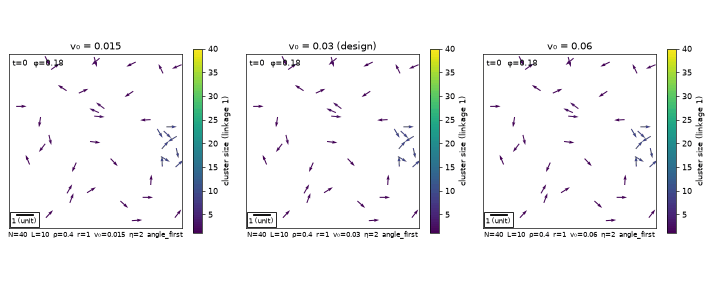

In [2]:
trs = [
    simulate(VicsekParams(eta=2.0, n=40, L=10.0, v0=v0), 1500, seed=4, record_every=3)
    for v0 in (0.015, 0.03, 0.06)
]
gif = animate(
    trs,
    "ordering_vs_v0",
    color="cluster",
    gif=Path("../figures/ordering_vs_v0.gif"),
    stride=3,
    fps=15,
    dpi=60,
    titles=["v₀ = 0.015", "v₀ = 0.03 (design)", "v₀ = 0.06"],
)
show(gif)

**How to read this.**
- **Early on** all three panels look alike: scattered particles, mostly small clusters.
- **By step ~600**, the fastest flock (v₀ = 0.06, right) has gathered into larger groups (φ ≈ 0.56 at that
  moment in the counter). The slower ones are still scattered (φ ≈ 0.1–0.3). Faster particles do meet sooner.
- **Caveat:** each panel is a *single* run, and φ fluctuates strongly at N = 40 (notebook 00 §2). One frame proves
  nothing. The quantitative answer is in §2–§5, averaged over many runs.

## 2. The protocol applied: curves and windows

For both noise levels (η = 2, left; η = 1, right) and both observables (φ top, nn_dist bottom):
- Each thin line is **one group's gap to its plateau**, $g_m(t)$, on a **log scale**. A single exponential
  approach would be a straight descending line.
- The **shaded band** is the window the protocol picked for that group, from where the gap reaches
  0.8·g(0) to where it reaches 0.2·g(0).

The table below the figure lists, per group, the fitted rate λ, the rates of the two halves, whether they
pass the single-rate check, and the half-time t½.

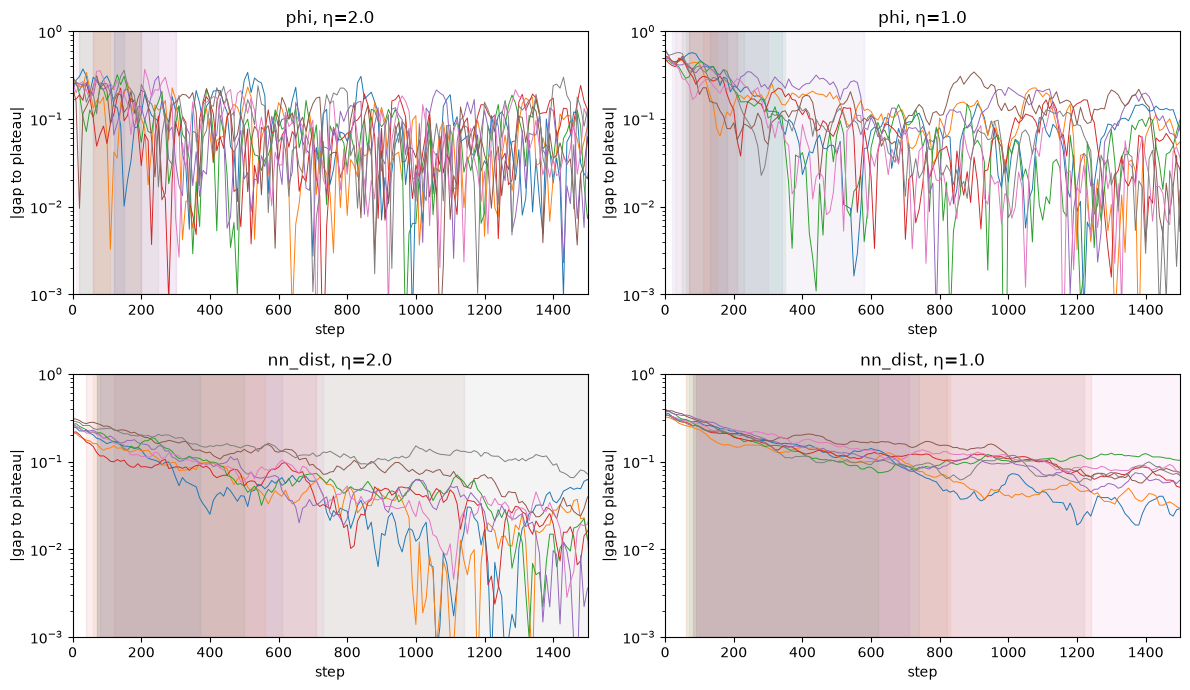

In [3]:
rel = {eta: relaxation(eta) for eta in P}

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, eta in enumerate(P):
    o = rel[eta]
    for row, name in enumerate(("phi", "nn_dist")):
        ax = axes[row, col]
        t = o[f"{name}_t"]
        curves = o[f"{name}_curve"]
        for j in range(curves.shape[1]):
            y = curves[:, j]
            y_inf = y[(t >= 4000) & (t <= 6000)].mean()
            g = np.abs(y_inf - y)
            (line,) = ax.semilogy(t, g, lw=0.7)
            ta, tb = o[f"{name}_t_a"][j], o[f"{name}_t_b"][j]
            if np.isfinite(ta):
                ax.axvspan(ta, tb, color=line.get_color(), alpha=0.08)
        ax.set(
            xlim=(0, 1500),
            ylim=(1e-3, 1),
            title=f"{name}, η={eta}",
            xlabel="step",
            ylabel="|gap to plateau|",
        )
plt.tight_layout()

In [4]:
for eta in P:
    o = rel[eta]
    for name in ("phi", "nn_dist"):
        print(f"η={eta}  {name}")
        print("   group    λ (1/step)    λ first half   λ second half   single?   t½ (steps)")
        for j in range(8):
            print(
                f"   {j:5d} {o[f'{name}_lam'][j]:12.4f} {o[f'{name}_lam_1'][j]:14.4f} {o[f'{name}_lam_2'][j]:15.4f}"
                f" {str(bool(o[f'{name}_single'][j])) if np.isfinite(o[f'{name}_single'][j]) else 'n/a':>9s} {o[f'{name}_t_half'][j]:12.0f}"
            )

η=2.0  phi
   group    λ (1/step)    λ first half   λ second half   single?   t½ (steps)
       0       0.0839         0.0261             nan     False          140
       1       0.0605        -0.0081          0.1999     False          100
       2      -0.0006        -0.0068          0.0141     False           30
       3      -0.0016        -0.0099          0.0188     False           70
       4       0.0018        -0.0021          0.0133     False          120
       5          nan            nan             nan       n/a           20
       6       0.0029         0.0012          0.0034     False          170
       7       0.0035        -0.0017          0.0160     False           70
η=2.0  nn_dist
   group    λ (1/step)    λ first half   λ second half   single?   t½ (steps)
       0       0.0048         0.0027          0.0066     False          210
       1       0.0023         0.0023          0.0030      True          260
       2       0.0027         0.0012          0.0039     F

**How to read the figure and the table.**

**φ (top panels): the protocol reaches the noise floor.**
- The gap falls quickly within ~100–300 steps to about 0.1, and then **does not keep decreasing**. It
  jitters around ~0.1 for the rest of the run.
- That jitter is the **noise floor**: even the mean of 5 replicas fluctuates by about 0.1, which is at or
  above 0.2·g(0) (the gap starts at ~0.3 for η = 2 and ~0.5–0.6 for η = 1).
- So the "0.2·g(0)" end of the window is reached by a random dip, not by relaxation. The windows are only
  a few frames long.
- **In the table:**
  - some fitted rates are **negative** (the gap "grows" inside the window);
  - one group (η = 2, group 5) cannot be fitted at all;
  - the single-rate check fails in 14 of 16 groups.
- By the protocol's own rule, **no rate is reported for φ.**

**nn_dist (bottom panels): positive rates, and two regimes rather than one exponential.**
- The gap descends steadily over ~1000 steps, so the windows are long and the rates positive
  (λ ≈ 0.0006–0.005 per step).
- But the rates differ by a **factor ~5** between groups of the same parameters.
- The single-rate check fails in 9 of 16 groups: the log-gap is curved, not straight. There is a fast phase
  (local groups form) and a slow phase (groups merge).

**t½ is defined for every group of both observables:**
- φ: 20–170 steps at η = 2 and 70–200 at η = 1;
- nn_dist: 110–490 at η = 2 and 160–370 at η = 1.

It is the robust number of this notebook.

## 3. Pre-registered sensitivity: do t½ and λ carry information about θ?

Even if a rate is noisy, it could still be informative: it would be enough that it *moves* with the
parameters by more than its noise. This is the same question and the same z as in notebook 01, now for the
group-level quantities t½ and λ.

For a group-level quantity $Q_m$ ($t_{1/2,m}$ or $\lambda_m$) and a parameter $q \in \{\eta, r, v_0\}$
(`flockladder.sensitivity`, the same convention as in notebook 01):
- Run the same seeds at $q\,e^{\pm 0.1}$, so every group $m$ has a matched pair $Q^\pm_m$.

$$D_m = \frac{Q^+_m - Q^-_m}{0.2} \approx \frac{\partial Q}{\partial \log q}, \qquad
z_q = \frac{0.1\ \overline{D}}{\operatorname{sd}_m(Q_m)}, \qquad
\operatorname{se}(z_q) = \frac{0.1\ \operatorname{sd}_m(D_m)/\sqrt{M}}{\operatorname{sd}_m(Q_m)}$$

$z_q$ is how many between-group sds (groups of 5 replicas) a 10% change of $q$ moves $Q$. The sd is
computed at the central θ.

In [5]:
for eta, p in P.items():
    T = table(unpack_sensitivity(f"sens_eta{eta}", R))  # = sensitivity(p, runner=run_relaxation)
    print(f"η={eta}")
    for s in ("phi_t_half", "phi_lam", "nn_dist_t_half", "nn_dist_lam"):
        r = T[s]
        zs = "  ".join(
            f"z_{q}={r['z_' + q]:+.2f}±{r['z_' + q + '_se']:.2f}" for q in ("eta", "r", "v0")
        )
        print(f"   {s:15s} mean={r['mean']:9.4g}  sd={r['sd']:8.3g}   {zs}")

η=2.0
   phi_t_half      mean=       90  sd=    52.4   z_eta=-0.33±0.18  z_r=+0.27±0.23  z_v0=-0.02±0.11
   phi_lam         mean=      nan  sd=     nan   z_eta=+nan±nan  z_r=+nan±nan  z_v0=+nan±nan
   nn_dist_t_half  mean=    267.5  sd=     115   z_eta=-0.22±0.11  z_r=+0.01±0.22  z_v0=-0.21±0.20
   nn_dist_lam     mean= 0.002026  sd= 0.00132   z_eta=+0.18±0.24  z_r=+0.21±0.23  z_v0=+0.15±0.38
η=1.0
   phi_t_half      mean=    142.5  sd=      45   z_eta=+0.15±0.20  z_r=-0.72±0.37  z_v0=-0.24±0.24
   phi_lam         mean= 0.009769  sd=  0.0111   z_eta=-0.06±0.09  z_r=+0.20±0.12  z_v0=-0.12±0.13
   nn_dist_t_half  mean=    258.8  sd=    59.9   z_eta=-0.03±0.20  z_r=+0.53±0.54  z_v0=-0.58±0.31
   nn_dist_lam     mean= 0.001399  sd=0.000552   z_eta=-0.06±0.18  z_r=-0.20±0.43  z_v0=+0.52±0.33


**How to read this.**
- **Every |z| is below 1**, and most are below 0.5. A 10% change of any parameter shifts t½ or λ by less
  than one group-to-group standard deviation.
- The reason is visible in the `sd` column: **the spread between groups is 30–60% of the mean**
  (e.g. t½ of φ at η = 2 is 90 ± 52 steps).
- `phi_lam` at η = 2 is `nan` because one group could not be fitted (§2).
- **H1 as registered is not supported.**

That does not yet say whether the rates are *insensitive*, or only *imprecise*. A tiny response hidden by
a huge noise and no response at all give the same |z| < 1. §5 separates the two.

## 4. Cost of precision

If the rates *do* respond but weakly, we could still use them by averaging many groups. How many?

Averaging $n$ groups divides the sd by $\sqrt n$. So resolving a 10% change at $2\sigma$ needs

$$n = \left(\frac{2}{|z|}\right)^2 \text{ groups.}$$

With $|z| \approx 0.2$–$0.5$, that is about 16–100 groups, or 80–500 replicas. Compare notebook 01, where `speed`, `cos_turn` and `corr_0_1` resolve
10% in a *single* replica run.

## 5. Exploratory (not pre-registered): large changes of v₀

Is the null in §3 insensitivity, or just resolution? Halve and double v₀, same protocol, same seeds.
Error bars are the standard error over groups, $\operatorname{sd}_m(t_{1/2,m})/\sqrt{M}$. The printed
elasticity is the least-squares slope over the three points

$$\epsilon = \frac{d \log \langle t_{1/2}\rangle}{d \log v_0}$$

A pure encounter-time argument would give $\epsilon = -1$ (the dotted reference line).

phi      η=2.0: t½ = 149, 90, 65 steps;  d log t½ / d log v₀ ≈ -0.60
nn_dist  η=2.0: t½ = 819, 268, 71 steps;  d log t½ / d log v₀ ≈ -1.76
phi      η=1.0: t½ = 219, 142, 88 steps;  d log t½ / d log v₀ ≈ -0.66
nn_dist  η=1.0: t½ = 615, 259, 95 steps;  d log t½ / d log v₀ ≈ -1.35


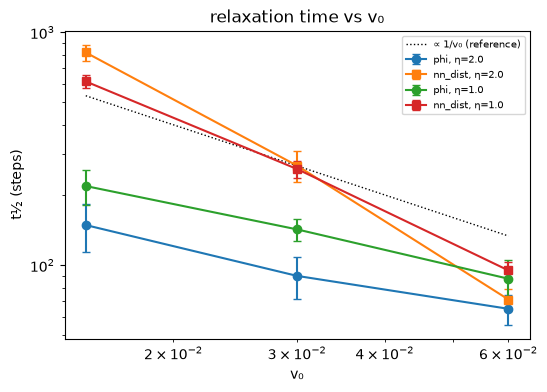

In [6]:
V0 = (0.015, 0.03, 0.06)
fig, ax = plt.subplots(figsize=(6, 4))
for eta, p in P.items():
    for name, m in (("phi", "o"), ("nn_dist", "s")):
        th = [relaxation(eta, v0)[f"{name}_t_half"] for v0 in V0]
        mean = [np.nanmean(x) for x in th]
        se = [np.nanstd(x, ddof=1) / np.sqrt(np.isfinite(x).sum()) for x in th]
        ax.errorbar(V0, mean, yerr=se, marker=m, capsize=3, label=f"{name}, η={eta}")
        slope = np.polyfit(np.log(V0), np.log(mean), 1)[0]
        print(
            f"{name:8s} η={eta}: t½ = {', '.join(f'{x:.0f}' for x in mean)} steps;  d log t½ / d log v₀ ≈ {slope:.2f}"
        )
v = np.array(V0)
ax.loglog(v, 267 * (0.03 / v), "k:", lw=1, label="∝ 1/v₀ (reference)")
ax.set(xlabel="v₀", ylabel="t½ (steps)", title="relaxation time vs v₀")
ax.legend(fontsize=7);

**How to read this.** Points are the mean t½ over the 8 groups, with the standard error as error bars. Both
axes are logarithmic, so a power law is a straight line. The dotted line is the naive reference t½ ∝ 1/v₀
("the time to travel a fixed distance").

- **The rates are strongly sensitive to v₀.** Going from v₀ = 0.015 to 0.06 (×4):
  - divides t½ of **nn_dist** by ~11.5 at η = 2 (819 → 71 steps) and by ~6.5 at η = 1 (615 → 95). The slopes are
    −1.76 and −1.35, *steeper* than the naive −1: faster particles meet more often *and* travel further
    between meetings.
  - divides t½ of **φ** by ~2.3 (149 → 65) and ~2.5 (219 → 88), with slopes ≈ −0.6: local alignment
    depends less on meeting others.
- **So the null of §3 is imprecision, not insensitivity.** The elasticity is large, but a 10% change moves
  t½ by only ~6–18%, while the group-to-group spread is 30–60%.
- **Caveat:** at v₀ = 0.015 the nn_dist relaxation is slow (t½ ≈ 600–800). The plateau window
  (4000–6000 steps) is then only ~5 t½ after the start, so that point is less clean.

## 6. What this taught us

**A rate answers its own question, and only that.** "How fast does it order?"
- At the design point, φ reaches half its gap in ~90 steps at η = 2 and ~140 at η = 1.
- The geometry (nn_dist) takes ~260 steps.
- The spread between groups of 5 replicas is 30–60%.
- *If the goal is that number, stop here:* report t½ with its spread. Do not fit a single exponential.

**The relaxation has more structure than a single rate** (reported as found).
- For φ, the pre-registered log-linear window meets the noise floor: it sits at the 0.2·g(0) threshold.
- The single-rate check fails for 14 of 16 φ groups (one more could not be fitted at all) and 9 of 16
  nn_dist groups.
- The relaxation has at least two regimes: fast local alignment, then slow merging of groups.

**H1: the transient does carry v₀, but not with useful precision.**
- Exploratory §5: d log t½ / d log v₀ ≈ −1.4 to −1.8 for nn_dist, steeper than the naive 1/v₀, and ≈ −0.6
  for φ.
- So the rates are *sensitive*: their elasticity to v₀ is large, unlike every stationary alignment
  summary in notebook 01.
- But they are *imprecise*: a 10% change needs ~100 groups.
- The stationary `speed` pins v₀ in one run. As long as tracking noise is absent, the transient adds
  nothing that `speed` does not already give.
- **Reason to come back:** once tracking noise degrades `speed` (future rung), the transient may become
  the better handle on v₀.
- **Caveat:** at v₀ = 0.015 the geometric plateau window (4000–6000 steps) is only ~5 t½ from the
  start, so that point is less clean.

**What notebook 03 adds.** A rate answers *how fast* the flock orders; notebook 03 asks *which* θ produced the data.
A rate gives one noisy number per run, and notebook 01 showed that η and r trade off along a ridge in most summaries.
Notebook 03 fits θ from a vector of stationary summaries, where notebook 01 found single-run resolution.